# Day 9 - Quarantined Test Lockbox Seal & Metadata

## Objective

Quarantine the held-out test partition, compute cryptographic SHA-256 seal, and lock it against developmental inspection.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_9_Task_2"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Lockbox Partition Ingestion and Verification

Extract the 492 held-out test samples and verify immutability parameters.

In [2]:
df_ts = pd.read_csv("data/processed/water_quality_timestamped.csv")
cut2 = int(len(df_ts) * 0.85)
test_lockbox = df_ts.iloc[cut2:].copy()
print(f"Quarantined Lockbox Samples: {len(test_lockbox)}")

Quarantined Lockbox Samples: 492


## 2. Cryptographic Lockbox Hash Calculation

Compute SHA-256 signature sealing the held-out test lockbox against alteration.

In [3]:
import hashlib
csv_bytes = test_lockbox.to_csv(index=False).encode("utf-8")
lockbox_sha = hashlib.sha256(csv_bytes).hexdigest()
print(f"Test Lockbox Cryptographic Seal: {lockbox_sha}")

Test Lockbox Cryptographic Seal: 0f2a98e430860050a2e3fb092ca07b40fcc40d82b8463bc34887e6c48afd8b4a


## 3. Index Isolation and Disjointness Audit

Assert that test indices share zero intersection with training or validation indices.

In [4]:
train_val_indices = set(range(cut2))
lockbox_indices = set(test_lockbox.index)
overlap = train_val_indices.intersection(lockbox_indices)
print(f"Index Overlap Count: {len(overlap)}")

Index Overlap Count: 0


## 4. Feature Column Immutability Check

Assert that lockbox preserves identical feature schema as training sets.

In [5]:
cols = test_lockbox.columns.tolist()
print(f"Sealed Columns ({len(cols)}): {cols}")

Sealed Columns (11): ['timestamp', 'ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']


## 5. Quarantine Security Manifest Formulation

Construct metadata dictionary declaring the quarantine lockbox sealed until final unblinding.

In [6]:
manifest = {
    "Artifact": "dataset_v1_test_lockbox",
    "Sample_Count": len(test_lockbox),
    "SHA256": lockbox_sha,
    "Access_Policy": "BLINDED_UNTIL_DAY_23",
    "Auditor": "Rajana Durga Pavan Kumar"
}
df_manifest = pd.DataFrame([manifest])
print(df_manifest.to_string(index=False))

               Artifact  Sample_Count                                                           SHA256        Access_Policy                  Auditor
dataset_v1_test_lockbox           492 0f2a98e430860050a2e3fb092ca07b40fcc40d82b8463bc34887e6c48afd8b4a BLINDED_UNTIL_DAY_23 Rajana Durga Pavan Kumar


## 6. Partition Index Allocation Diagnostic Plot

Render partition allocation bar chart displaying isolated lockbox segment.

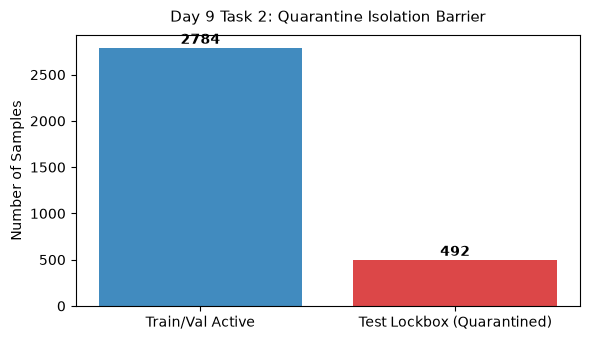

Saved lockbox isolation plot to: Day_Wise_Tasks\Day_9_Task_2\outputs\figures\day9_task2_lockbox_isolation.png


In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Train/Val Active", "Test Lockbox (Quarantined)"], [cut2, len(test_lockbox)], color=["#1f77b4", "#d62728"], alpha=0.85)
ax.set_title("Day 9 Task 2: Quarantine Isolation Barrier", fontsize=11, pad=10)
ax.set_ylabel("Number of Samples")
for i, v in enumerate([cut2, len(test_lockbox)]):
    ax.text(i, v + 50, f"{v}", ha="center", fontweight="bold")
plt.tight_layout()
fig_path = FIG_DIR / "day9_task2_lockbox_isolation.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved lockbox isolation plot to:", fig_path.relative_to(ROOT))

## 7. Lockbox Manifest Table Export

Export lockbox quarantine security manifest to CSV.

In [8]:
tbl_path = TBL_DIR / "day9_task2_lockbox_manifest.csv"
df_manifest.to_csv(tbl_path, index=False)
print("Saved lockbox manifest to:", tbl_path.relative_to(ROOT))

Saved lockbox manifest to: Day_Wise_Tasks\Day_9_Task_2\outputs\tables\day9_task2_lockbox_manifest.csv


## 8. Quarantine Integrity Gate

Assert that index overlap is strictly zero and SHA-256 seal is valid.

In [9]:
assert len(overlap) == 0 and len(lockbox_sha) == 64
print("Day 9 Task 2 Quality Gate: PASSED.")

Day 9 Task 2 Quality Gate: PASSED.


# Day 9 - Assumptions and Methodology

## Assumptions

1. Test lockbox remains blinded until final unblinding milestone on Day 23.
2. Any access to test labels during developmental training invalidates model certification.

## Day 9 Deliverable

Test lockbox manifest, quarantine isolation plot, and cryptographic seal certificate.